# Week 3 — Painting detection (QSD2-W3)

Step-by-step walkthrough of `detect_paintings` from `w3/utils.py`. Images are assumed to be **already denoised**, so by default the notebook uses the clean images in `qsd2_w3/non_augmented`.

**Pipeline**
1. **Colour cue**: Mahalanobis distance of every pixel to the wall (modelled on the image border) + Otsu (Week 2 method).
2. **Edge cue**: high-pass filter (Prewitt) on the grey image + Otsu, then each group of edges (a frame) is filled with its convex hull.
3. **Fusion** of both cues + morphological clean-up.
4. **Candidate selection**: connected components, keep at most 2 that are big and rectangular.
5. **Shape fitting** (quadrilateral) and **ordering** left→right / top→bottom.
6. **Evaluation** on the whole set (pixel precision / recall / F1 / IoU + painting count).

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import utils as U

DATA_DIR = Path("..") / "data" / "qsd2_w3"
IMAGE_DIR = DATA_DIR / "non_augmented"   # clean images; use DATA_DIR for the augmented ones

ids = sorted(int(p.stem) for p in IMAGE_DIR.glob("*.jpg"))
images = {i: cv2.imread(str(IMAGE_DIR / f"{i:05d}.jpg")) for i in ids}
gts = {i: cv2.imread(str(IMAGE_DIR / f"{i:05d}.png"), cv2.IMREAD_GRAYSCALE) > 0 for i in ids}
n_gt = {i: cv2.connectedComponents(gts[i].astype(np.uint8))[0] - 1 for i in ids}

print(f"{len(ids)} images | 1 painting: {sum(v == 1 for v in n_gt.values())} | 2 paintings: {sum(v == 2 for v in n_gt.values())}")
U.DEFAULT_PARAMS

30 images | 1 painting: 21 | 2 paintings: 9


{'color_space': 'HSV',
 'channels': [1, 2],
 'edge_operator': 'prewitt',
 'blur_ksize': 5,
 'edge_close_frac': 0.01,
 'edge_fill': 'hull',
 'fusion': 'or',
 'open_frac': 0.02,
 'min_area_frac': 0.02,
 'min_rel_area': 0.15,
 'min_rectangularity': 0.75,
 'fit': 'poly'}

In [2]:
def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def show(panels, cols=None, size=4):
    """panels: list of (title, image). Grey images are shown with a grey colormap."""
    cols = cols or len(panels)
    rows = int(np.ceil(len(panels) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, img) in zip(axes.flat, panels):
        ax.imshow(img, cmap=None if img.ndim == 3 else "gray")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()


def overlay(img, masks, alpha=0.45):
    """Draw each painting mask in a different colour with its order number."""
    colors = [(255, 60, 60), (60, 160, 255), (60, 220, 60), (255, 200, 0)]
    out = rgb(img).copy()
    for k, m in enumerate(masks):
        color = np.array(colors[k % len(colors)])
        sel = m > 0
        out[sel] = ((1 - alpha) * out[sel] + alpha * color).astype(np.uint8)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, contours, -1, color.tolist(), 3)
        x, y, w, h = cv2.boundingRect(m.astype(np.uint8))
        cv2.putText(out, str(k + 1), (x + w // 2, y + h // 2), cv2.FONT_HERSHEY_SIMPLEX,
                    2, (255, 255, 255), 5)
    return out

## 0. Pick an image
Change `IDX` to inspect any image. Interesting ones: `2` (two paintings, one small), `21` (painting colours close to the wall), `29` (two paintings with frame depth).

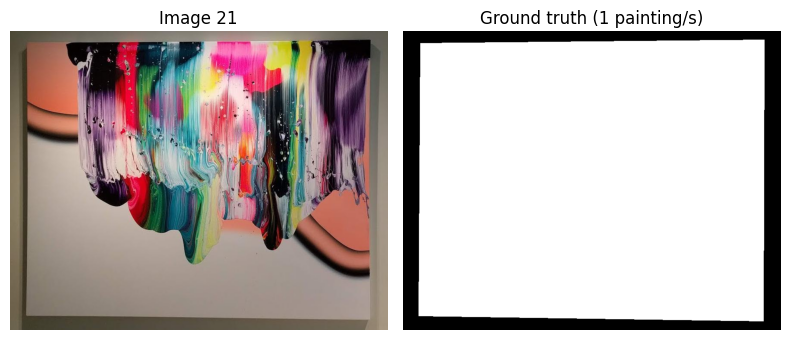

In [20]:
IDX = 21
img, gt = images[IDX], gts[IDX]
debug = U.detect_paintings_debug(img)
show([(f"Image {IDX}", rgb(img)), (f"Ground truth ({n_gt[IDX]} painting/s)", gt)])

## 1. Colour cue (Week 2 method)
The wall colour is modelled with a Gaussian fitted on the border pixels (S and V channels of HSV, so hue changes do not matter). Every pixel gets its Mahalanobis distance to that model, and Otsu separates wall from painting.

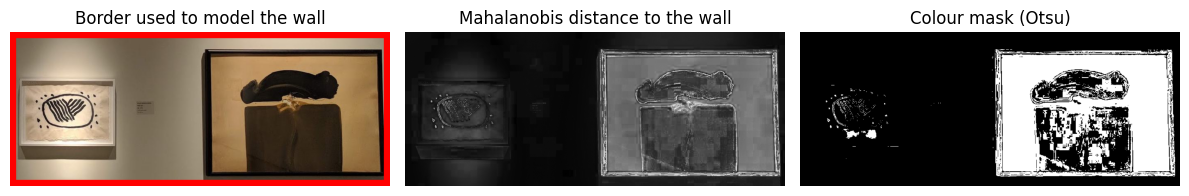

In [4]:
h, w = img.shape[:2]
border = U.border_mask(h, w)
border_vis = rgb(img).copy()
border_vis[border] = (255, 0, 0)

show([
    ("Border used to model the wall", border_vis),
    ("Mahalanobis distance to the wall", np.clip(debug["color_dist"], 0, 255)),
    ("Colour mask (Otsu)", debug["color_mask"]),
])

## 2. Edge cue (high-pass filters)
### 2.1 Prewitt gradients
Prewitt kernels approximate the horizontal and vertical derivatives. The magnitude $\sqrt{G_x^2 + G_y^2}$ is high on the painting frames. A small Gaussian blur is applied first so the wall texture does not produce edges.

Prewitt Gx kernel:
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]] 
Prewitt Gy kernel:
 [[-1. -1. -1.]
 [ 0.  0.  0.]
 [ 1.  1.  1.]]


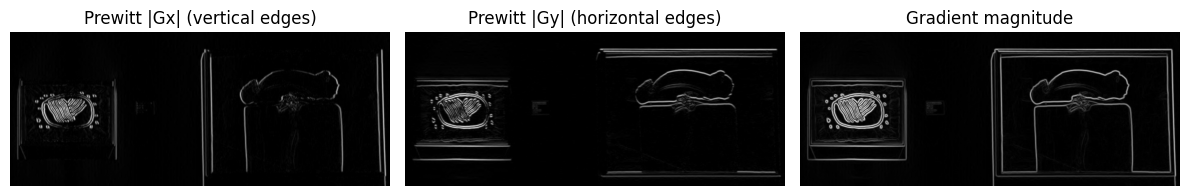

In [8]:
gray = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32), (5, 5), 0) #Maybe delete because of alis part.
kx, ky = U.EDGE_KERNELS["prewitt"]
gx = cv2.filter2D(gray, cv2.CV_32F, kx)
gy = cv2.filter2D(gray, cv2.CV_32F, ky)

print("Prewitt Gx kernel:\n", kx, "\nPrewitt Gy kernel:\n", ky)
show([
    ("Prewitt |Gx| (vertical edges)", np.abs(gx)),
    ("Prewitt |Gy| (horizontal edges)", np.abs(gy)),
    ("Gradient magnitude", debug["gradient"]),
])

### 2.2 Comparing high-pass operators

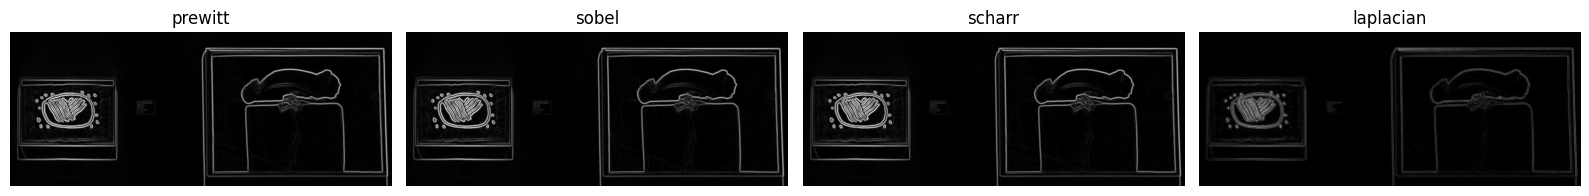

In [9]:
ops = ["prewitt", "sobel", "scharr", "laplacian"]
show([(op, U.gradient_magnitude(img, op, blur_ksize=5)) for op in ops])

### 2.3 From edges to regions
The magnitude is binarised with Otsu and slightly closed. Then two ways of turning the edges into filled regions:
- **flood**: flood fill the wall from the image border; whatever is not reached is enclosed by edges. Fails if the frame outline has a gap (the fill leaks inside).
- **hull** (default): fill the convex hull of every connected group of edges. Robust to small gaps in the frame.

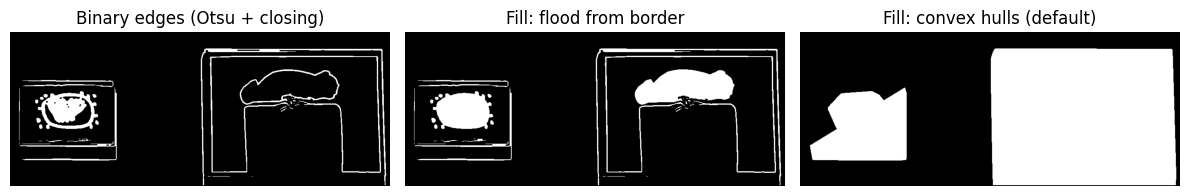

In [10]:
_, _, flood = U.edge_cue(img, fill="flood")
_, _, hull = U.edge_cue(img, fill="hull")
show([
    ("Binary edges (Otsu + closing)", debug["edges"]),
    ("Fill: flood from border", flood),
    ("Fill: convex hulls (default)", hull),
])

## 3. Fusion and clean-up
The colour and edge masks are combined (`or` by default), holes are filled and an opening removes thin structures (and thin bridges joining two paintings).

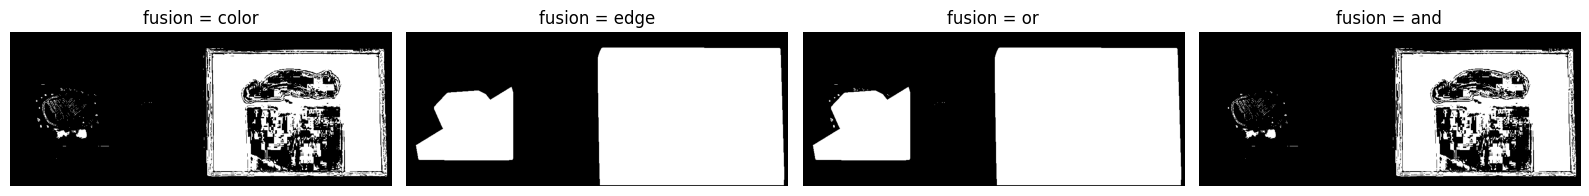

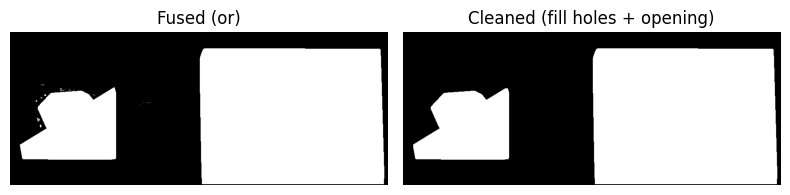

In [11]:
fusions = ["color", "edge", "or", "and"]
show([(f"fusion = {f}", U.fuse(debug["color_mask"], debug["edge_mask"], f)) for f in fusions])
show([("Fused (or)", debug["fused"]), ("Cleaned (fill holes + opening)", debug["cleaned"])])

## 4. Candidate selection
Each connected component is a candidate. It is kept if it is big enough (`min_area_frac` of the image), not much smaller than the largest one (`min_rel_area`) and rectangular (area / rotated rectangle area ≥ `min_rectangularity`). At most 2 are kept.

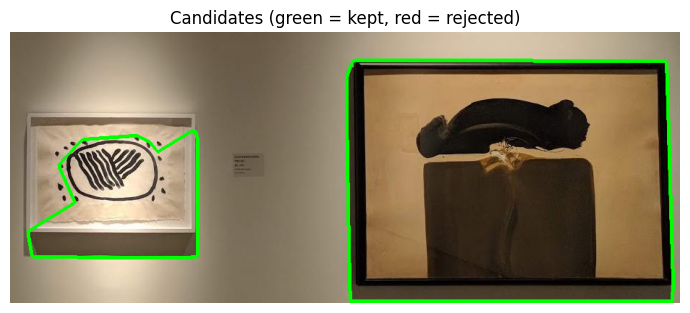

,label,area,rectangularity,bbox,kept,reasons
0,1,148286,0.990343,"[465, 40, 452, 333]",True,[]
1,2,32323,0.793865,"[25, 138, 235, 175]",True,[]


In [12]:
cand_vis = rgb(img).copy()
for c in debug["candidates"]:
    color = (0, 255, 0) if c["kept"] else (255, 0, 0)
    contours, _ = cv2.findContours(c["mask"], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(cand_vis, contours, -1, color, 3)
show([("Candidates (green = kept, red = rejected)", cand_vis)], size=7)

pd.DataFrame([{k: v for k, v in c.items() if k != "mask"} for c in debug["candidates"]]) \
    .sort_values("area", ascending=False)

## 5. Shape fitting and ordering
Paintings can be slightly rotated, so the blob is replaced by a quadrilateral. Masks are ordered left→right (top→bottom if stacked); this order must match the ground-truth order for retrieval.

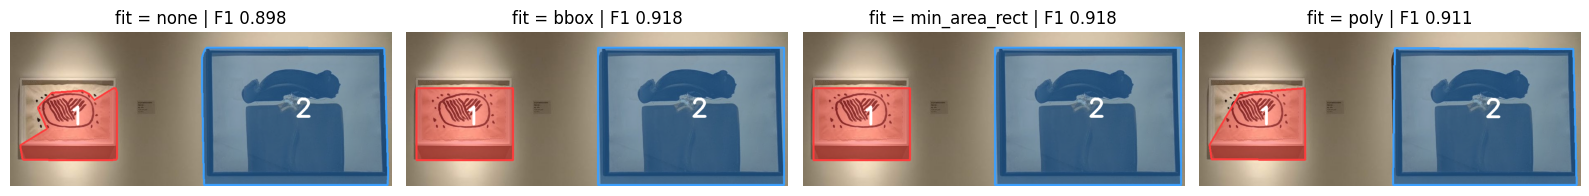

In [13]:
fits = ["none", "bbox", "min_area_rect", "poly"]
panels = []
for f in fits:
    masks = U.detect_paintings(img, fit=f)
    m = U.metrics(U.combined_mask(masks, img.shape), gt)
    panels.append((f"fit = {f} | F1 {m['f1']:.3f}", overlay(img, masks)))
show(panels)

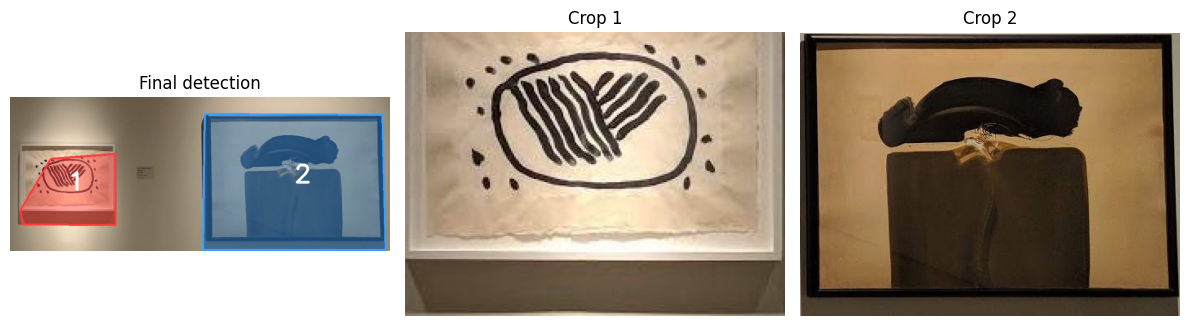

In [14]:
masks = debug["masks"]
crops = [U.crop_to_mask(img, m) for m in masks]
show([("Final detection", overlay(img, masks))] + [(f"Crop {k + 1}", rgb(c)) for k, c in enumerate(crops)])

## 6. Evaluation on the whole dataset

In [15]:
def evaluate_all(**params):
    rows, all_masks = [], {}
    for i in ids:
        masks = U.detect_paintings(images[i], **params)
        all_masks[i] = masks
        m = U.metrics(U.combined_mask(masks, images[i].shape), gts[i])
        rows.append({"id": i, "gt_count": n_gt[i], "pred_count": len(masks), **m})
    df = pd.DataFrame(rows).set_index("id")
    df["count_ok"] = df.gt_count == df.pred_count
    return df, all_masks


results, all_masks = evaluate_all()
print(f"Count accuracy: {results.count_ok.sum()}/{len(results)}")
results[["precision", "recall", "f1", "iou", "error_rate"]].mean().to_frame("mean")

Count accuracy: 30/30


,mean
precision,0.955918
recall,0.984851
f1,0.969733
iou,0.942189
error_rate,0.040292


In [16]:
# Worst images first
results.sort_values("f1").head(10)

,gt_count,pred_count,precision,recall,f1,iou,error_rate,count_ok
id,,,,,,,,
29,2,2,0.841029,0.992474,0.910497,0.835700,0.074793,True
2,2,2,0.892126,0.930095,0.910715,0.836067,0.090364,True
10,1,1,0.885855,0.995853,0.937639,0.882599,0.092534,True
22,1,1,0.897255,0.982238,0.937825,0.882929,0.087841,True
5,2,2,0.900890,0.989992,0.943342,0.892760,0.078234,True
17,1,1,0.936098,0.967998,0.951781,0.907998,0.072185,True
19,2,2,0.959090,0.960669,0.959878,0.922852,0.054136,True
27,1,1,0.945350,0.978930,0.961847,0.926498,0.058981,True
6,2,2,0.943819,0.986010,0.964453,0.931347,0.033328,True


### Gallery of all detections (red title = wrong painting count)

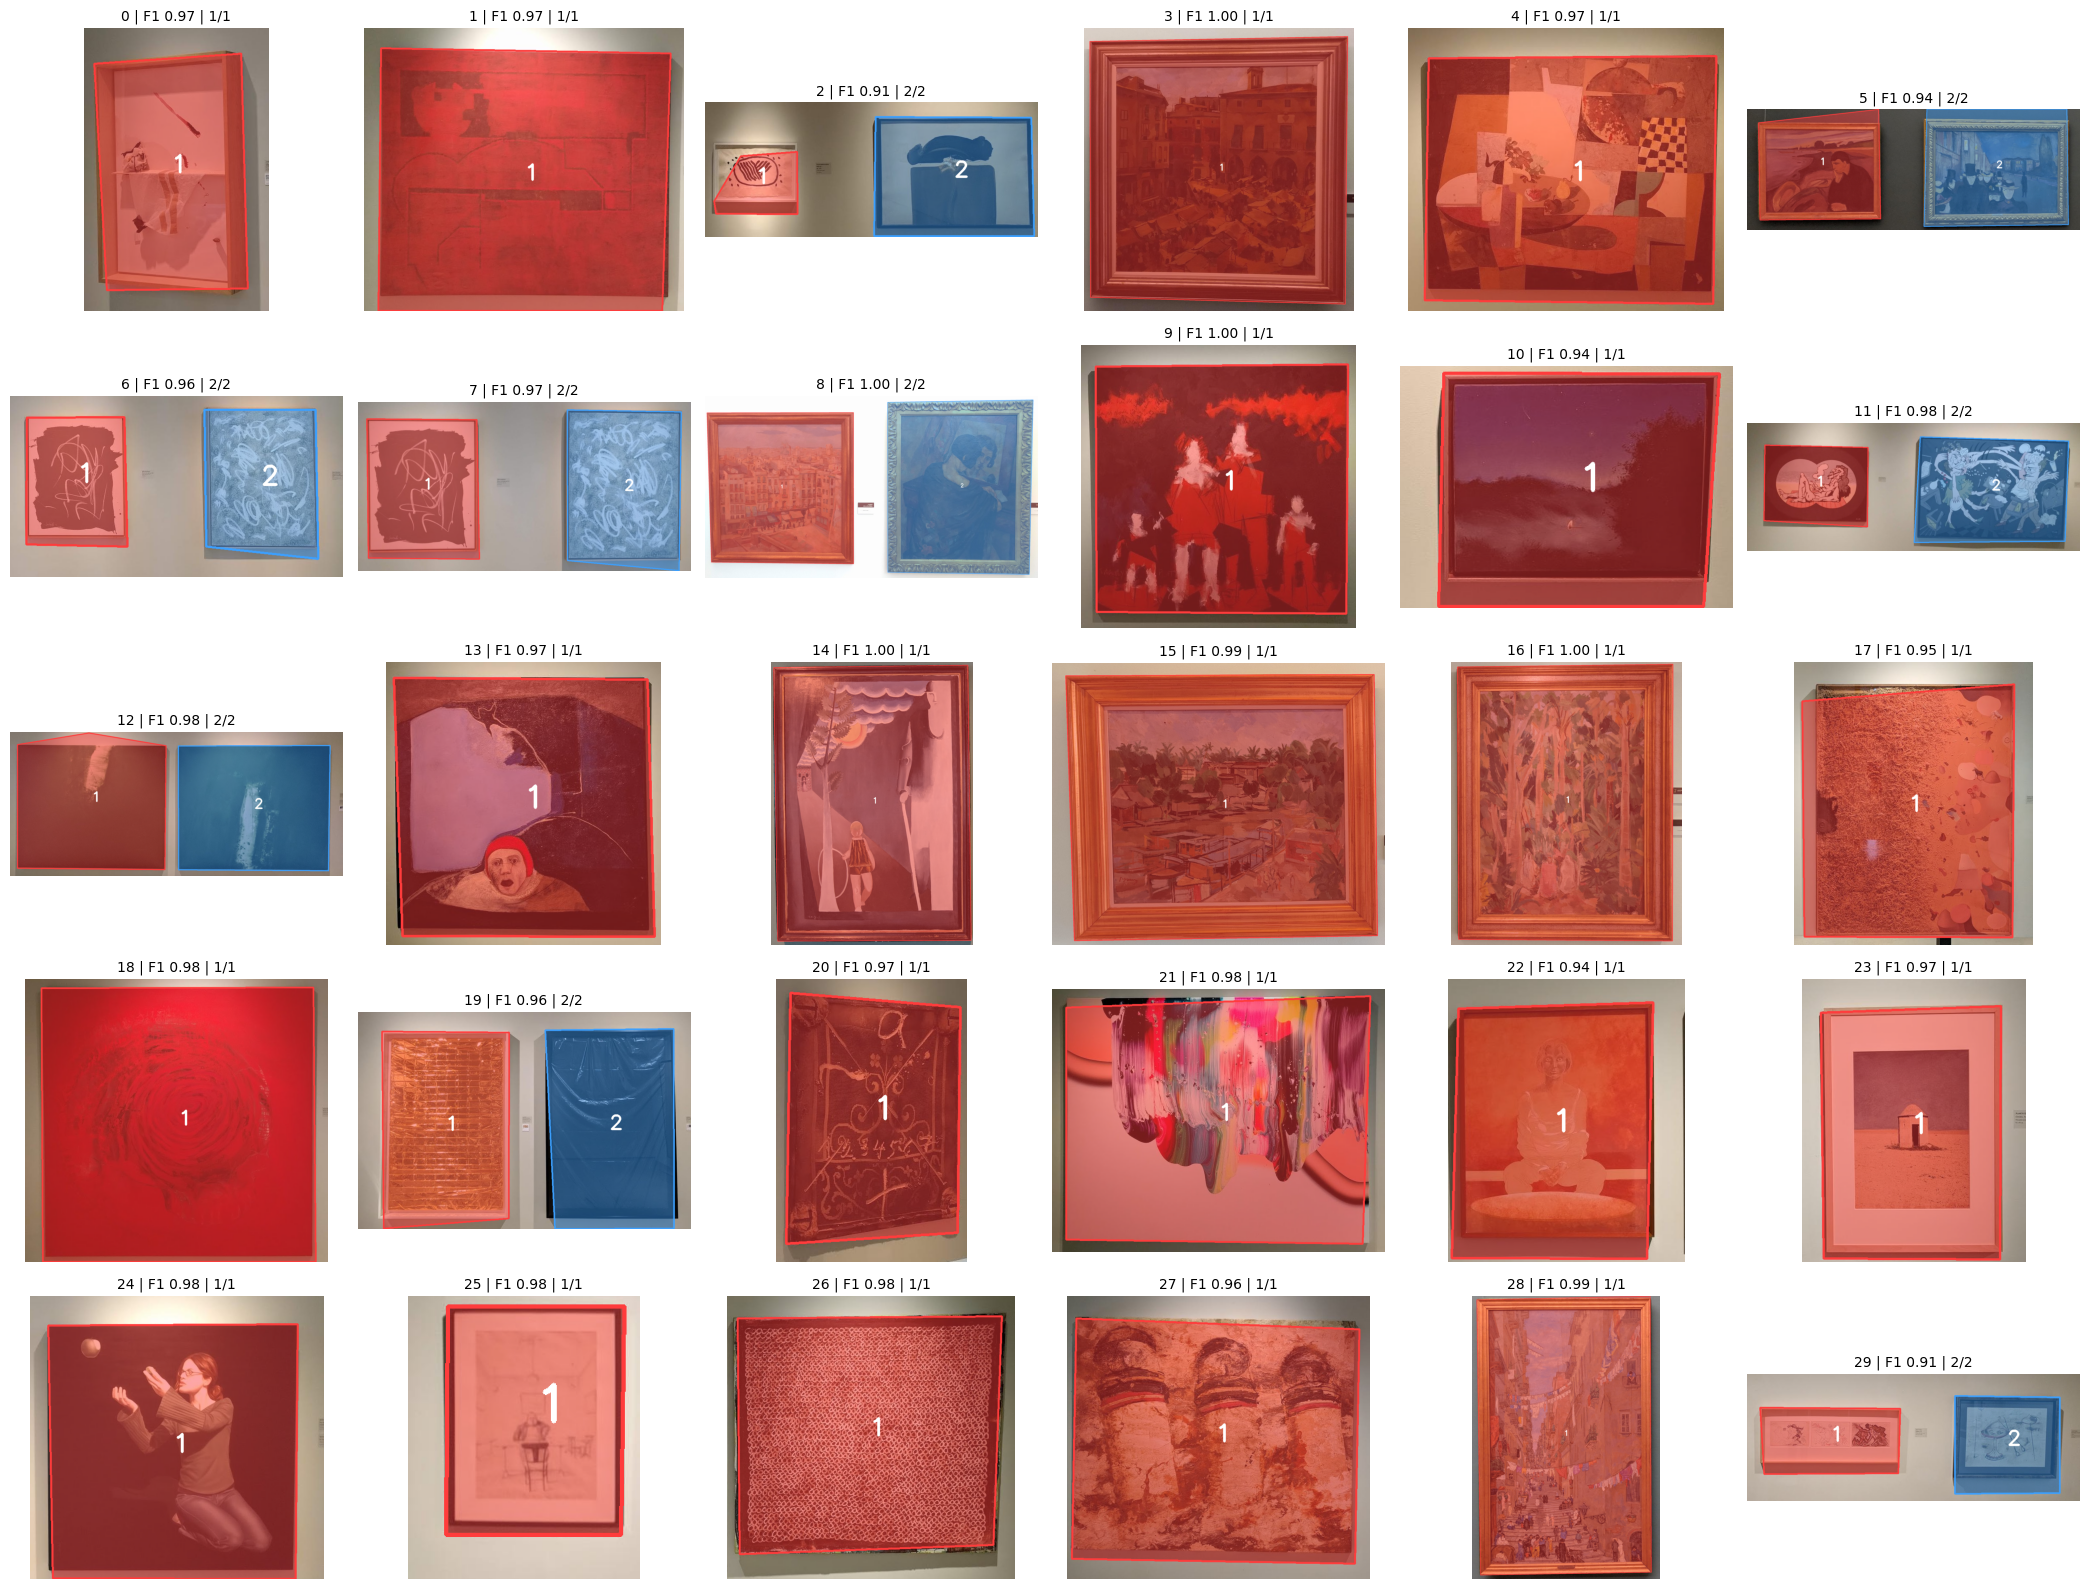

In [17]:
cols = 6
rows = int(np.ceil(len(ids) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(3.5 * cols, 3.2 * rows))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, ids):
    r = results.loc[i]
    ax.imshow(overlay(images[i], all_masks[i]))
    ax.set_title(f"{i} | F1 {r.f1:.2f} | {r.pred_count}/{r.gt_count}",
                 color="black" if r.count_ok else "red", fontsize=10)
plt.tight_layout()
plt.show()

## 7. Parameter comparison
Each row overrides some of the default parameters. Add your own configurations to `configs` to test new ideas.

In [18]:
configs = {
    "default": {},
    "colour only": {"fusion": "color"},
    "edges only": {"fusion": "edge"},
    "fusion and": {"fusion": "and"},
    "edge fill flood": {"edge_fill": "flood"},
    "sobel": {"edge_operator": "sobel"},
    "scharr": {"edge_operator": "scharr"},
    "laplacian": {"edge_operator": "laplacian"},
    "no blur": {"blur_ksize": 1},
    "Lab colour": {"color_space": "LAB", "channels": [1, 2]},
    "fit bbox": {"fit": "bbox"},
    "fit min_area_rect": {"fit": "min_area_rect"},
    "fit none": {"fit": "none"},
}

rows = []
for name, params in configs.items():
    df, _ = evaluate_all(**params)
    rows.append({"config": name, "count_acc": df.count_ok.mean(),
                 **df[["precision", "recall", "f1", "iou"]].mean().to_dict()})
pd.DataFrame(rows).set_index("config").sort_values("f1", ascending=False).style.format("{:.4f}")

,count_acc,precision,recall,f1,iou
config,,,,,
laplacian,1.0000,0.9632,0.9891,0.9755,0.9531
no blur,1.0000,0.9618,0.9867,0.9737,0.9496
sobel,1.0000,0.9561,0.9849,0.9699,0.9424
default,1.0000,0.9559,0.9849,0.9697,0.9422
Lab colour,1.0000,0.9571,0.9829,0.9693,0.9415
scharr,1.0000,0.9552,0.9848,0.9693,0.9414
edges only,1.0000,0.9572,0.9797,0.9678,0.9386
fit none,1.0000,0.9377,0.9942,0.9646,0.9327
fit min_area_rect,1.0000,0.9140,0.9986,0.9539,0.9129
